# **[실습 1] Logistic Regression**

## **데이터셋 설명**

여러 스타트업들의 지출 항목별 비용과 순이익에 대한 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| index | 번호 |
| hours_studied | 공부한 시간(H) |
| passed | 시험을 통과했다면1, 아니면 0 |

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/studies.csv

## **[1-1] Gradient Descent**

### **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

In [4]:
# code here
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/studies.csv")
df.head()

,index,hours_studied,passed
0,0,0.50,0
1,1,0.75,0
2,2,1.00,0
3,3,1.25,0
4,4,1.50,0


**Q2. 각 컬럼의 기본적인 정보를 확인하세요.**

In [2]:
# code here
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          20 non-null     int64  
 1   hours_studied  20 non-null     float64
 2   passed         20 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 612.0 bytes


**Q3. 수치형 컬럼들의 통계 요약을 확인하세요.**

In [3]:
# code here
df.describe()

,index,hours_studied,passed
count,20.00000,20.000000,20.000000
mean,9.50000,2.787500,0.500000
std,5.91608,1.507165,0.512989
min,0.00000,0.500000,0.000000
25%,4.75000,1.687500,0.000000
50%,9.50000,2.625000,0.500000
75%,14.25000,4.062500,1.000000
max,19.00000,5.500000,1.000000


### **2. 데이터 시각화하기**

**Q1. hours_studied를 독립변수로, passsed를 종속변수로 분리한다.**

In [50]:
# code here
X = df["hours_studied"]       # 독립변수 (input)
y = df["passed"]         # 종속변수 (ouput)

**Q2. 데이터를 산점도 그래프로 시각화한다.**

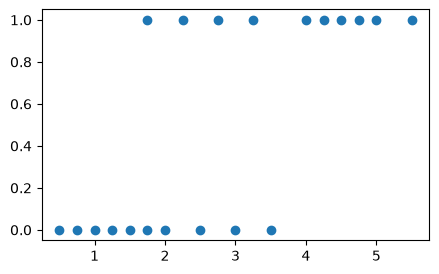

In [24]:
# code here
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(5,3))
plt.scatter(X, y)
plt.show()

In [ ]:
# 이 데이터의 line of best fit을 그려보자
from sklearn.linear_model import LinearRegression
import numpy as np

model = LinearRegression()
model.fit(np.array(X).reshape(-1, 1), y)
y_pred = model.predict(np.array(X).reshape(-1, 1))


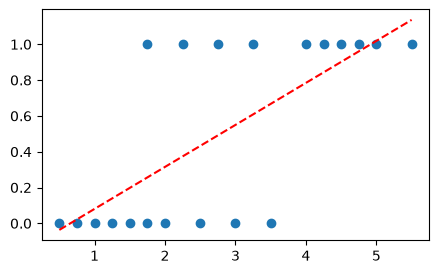

In [23]:
plt.figure(figsize=(5,3))
plt.scatter(X, y)
plt.plot(X, y_pred, linestyle = '--', color = 'red')
plt.show()

In [27]:
# sigmoid 함수를 만들어서, 값들을 0 ~ 1 사이로 만들기

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

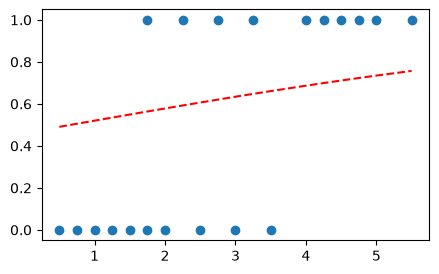

In [ ]:
y_pred = sigmoid(y_pred)

plt.figure(figsize=(5,3))   
plt.scatter(X, y)
plt.plot(X, y_pred, linestyle = '--', color = 'red')
plt.show()

In [ ]:
# 선형방정식 = coef_ , intercept_

# w = model.coef_
# b = model.intercept_
# print(w,b) 

[0.23459561] -0.15393526898848708


### **3. 모델링**

**Q1.LogisticRegression class를 생성한다.**
- 경사하강법을 구현하여 w(coefficient), b(intercept)를 구한다.

각 편미분 값은 다음과 같이 구할 수 있다.
- 𝝏𝒘 = (1/n) * np.sum((y_pred - y) * X)
- 𝛛𝒃 = (1/n) * np.sum(y_pred - y)

predict_proba(X) : X의 데이터가 1이 될 확률을 반환한다. 즉, 0.6이 나온다면, 60% 1(성공/통과) 라는 것이다.

predict(X) : predict_proba의 결과에서 0.5 이상이면 통과(1), 아니면 실패(0)로 변환하여 반환한다.

In [56]:
# code here
# from sklearn.metrics import accuracy_score

class LogisticRegression:

    def __init__(self):
        # 조정해야 하는 parameter 값들
        self.w = None  # 기울기
        self.b = None  # 절편
        self.history = None # loss 기록용

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))  # -> proba를 할 때 사용할 것

    def fit(self, X, y):
        #1. initialization : w,b를 어떤 랜덤값으로 설정
        self.w = 0.0
        self.b = 0.0
        self.history = []
        #2가지 설정
        lr = 0.1 #1. 학습률
        epochs = 1000 #2. epoch수
        n = X.size  #데이터의 개수만큼으로 평균 내기

        # 경사하강법 시작
        # epochs에 수만큼 변화를 주고 update
        for epoch in range(epochs):
            # 2. 지금의 self.w, sel.b를 기반으로 예측 결과를 내야함
            # 선형방정식
            z = self.w * X + self.b
            # 3. 결과를 sigmoid에 투입해서 0 ~ 1의 범주로 바꿔줌
            y_pred = self.sigmoid(z)

            # 변화량(미분/gradient)
            dw = (1/n) * np.sum((y_pred - y) * X)
            db = (1/n) * np.sum(y_pred - y)

            # 4. 변화량 만큼을 update
            # 주의: 변화량만큼을 더해주는것이 아닌 빼준다.
            self.w -= dw * lr
            self.b -= db * lr

            # loss = abs(y-y_pred).mean()
            epsilon = 1e-15
            loss = -np.mean(y * np.log(y_pred + epsilon) + (1 - y) * np.log(1 - y_pred + epsilon))
            self.history.append(loss)

            # 5. epoch마다 loss를 출력을 하기
            if (epoch + 1) % 100 == 0: # epoch이 100번 끝날 때마다 로그를 출력
                print(f"epoch {epoch} loss : {loss}")
            

    def predict(self, X):
        # 각 확률에 대해서, 우리가 설정한 threshold에 적합하면 1 아니면 0
        threshold = 0.5 # 50%를 넘어가면 1(통과), 아니면 0으로 분류
        return (self.predict_proba(X) > threshold).astype(int)

    def predict_proba(self, X):
        #각 데이터에 대한 확률을 나타냄
        return self.sigmoid(self.w * X + self.b)


In [57]:
# 모델 생성
model = LogisticRegression()

model.fit(X, y)

epoch 99 loss : 0.5196801285392678
epoch 199 loss : 0.4650054240237388
epoch 299 loss : 0.438749018041867
epoch 399 loss : 0.4246770128904818
epoch 499 loss : 0.41652332246404233
epoch 599 loss : 0.4115289123217834
epoch 699 loss : 0.4083428550872722
epoch 799 loss : 0.40624745270643886
epoch 899 loss : 0.40483666746312724
epoch 999 loss : 0.4038692099460327


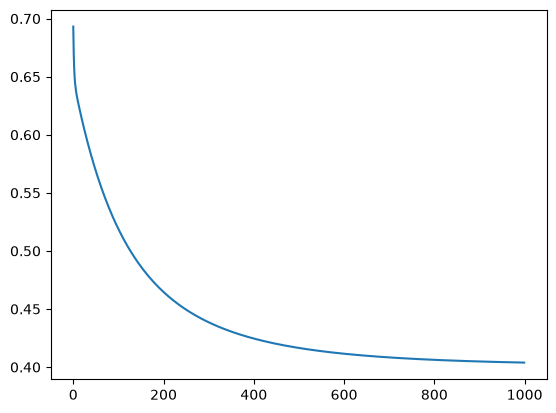

In [58]:
model.history
plt.plot(np.arange(0, 1000), model.history)
plt.show()

In [59]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X)
accuracy = accuracy_score(y, y_pred)
print(f"모델 분류 정확도: {accuracy * 100}%")

모델 분류 정확도: 80.0%


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(np.array(X).reshape(-1, 1), y)         # 결국 만들어진 모델들은 모두 matrix형태의 구조를 입력받길 원함!
model.predict(np.array(X).reshape(-1, 1))
model.predict_proba(np.array(X).reshape(-1, 1))  # predict_proba는 0이 될 확률과 1이될 확률을 []로 반환.


**Q2. 학습하기**

모델의 instance를 만들고, X, y를 사용해서 학습시킨다.

In [ ]:
# code here

**Q3. 예측하기**

predict_proba를 사용해서 예측 결과 (확률)을 y_pred에 저장한다.

In [ ]:
# code here

### **4. 결과 시각화하기**

X, y를 활용해서 산점도 그래프를 그린다.
- X, y_pred를 활용해서 선 그래프를 그린다. 선의 색은 빨간색으로 설정한다.

In [ ]:
# code here

## **[1-3] 모델 평가하기**

### **1. Confusion Matrix**

**Q1. 혼동행렬 구하기**

sklearn.metrics의 confusion_matrix를 활용하여 혼동행렬을 구하고 출력해본다.

In [60]:
# code here
from sklearn.metrics import confusion_matrix

y_pred = model.predict(X)

# 혼동 행렬 만들기
cm = confusion_matrix(y, y_pred)   #(실제값, 예측값)
print(cm)

[[8 2]
 [2 8]]


**Q2. 혼돈행렬 시각화하기**

seaborn의 heatmap을 활용하여 결과를 시각화한다.

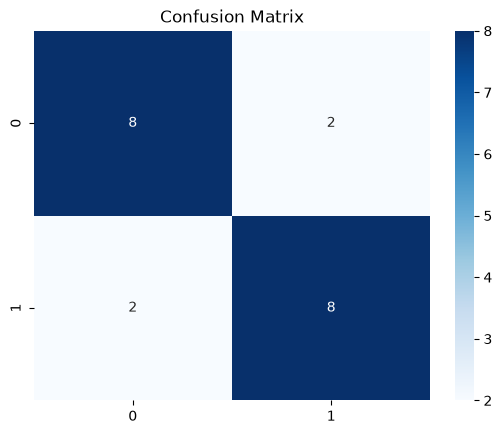

In [ ]:
# code here
# 높은 값일 수록 진하게 낮은값일수록 연하게
# 혼동행렬 시각화, 또는 다중공선성에 대한 연관도를 시각화
import seaborn as sns


plt.title("Confusion Matrix")
    
sns.heatmap(cm, annot=True, cmap = 'Blues')  #annot=True -> cm에 적혀있던 값을 적는다.
plt.show()

### **2. Classification Report**

**Q1. 정확도 출력하기**

In [68]:
# code here
from sklearn.metrics import accuracy_score

print(accuracy_score(y, y_pred) * 100)

80.0


**Q2. 분류 리포트 출력하기**

In [70]:
# code here
from sklearn.metrics import classification_report

print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.80      0.80        10
           1       0.80      0.80      0.80        10

    accuracy                           0.80        20
   macro avg       0.80      0.80      0.80        20
weighted avg       0.80      0.80      0.80        20

